# GIS Programming – Lab: Geospatial Data Formats and CRS (fixed)
Fixes vs. the handout: A2 Arabic string, A4 validator, per-city UTM zones (B), robust GADM download with fallback (C), `AREA_OR_POINT` tag removed and real nodata cells added (D), windowed single-pixel read (D5).

## Part A – GeoJSON

In [1]:
import json, os
import numpy as np
import matplotlib.pyplot as plt
data_dir = "data"; os.makedirs(data_dir, exist_ok=True)

### A1 – Algeria cities
Note: populations are approximate (wilaya-level figures are often quoted for these cities).

In [2]:
def pt(name, name_ar, lon, lat, **props):
    return {"type":"Feature","geometry":{"type":"Point","coordinates":[lon,lat]},
            "properties":{"name":name,"name_ar":name_ar,**props}}

algeria_cities_geojson = {"type":"FeatureCollection","features":[
    pt("Algiers","الجزائر",3.0588,36.7538,population=2988145,is_capital=True,wilaya_code=16),
    pt("Oran","وهران",-0.6331,35.6969,population=1454078,is_capital=False,wilaya_code=31),
    pt("Constantine","قسنطينة",6.6147,36.3650,population=938475,is_capital=False,wilaya_code=25),
]}
algeria_geojson_path = os.path.join(data_dir,"algeria_cities.geojson")
with open(algeria_geojson_path,"w",encoding="utf-8") as f:
    json.dump(algeria_cities_geojson,f,indent=2,ensure_ascii=False)
print("Saved:",algeria_geojson_path,os.path.getsize(algeria_geojson_path),"bytes")
with open(algeria_geojson_path,encoding="utf-8") as f: loaded=json.load(f)
print(f"Loaded {len(loaded['features'])} features:")
for ft in loaded["features"]:
    lon,lat=ft["geometry"]["coordinates"]
    print(f"  {ft['properties']['name']}: ({lat:.4f}N, {lon:.4f}E), pop {ft['properties']['population']:,}")

Saved: data/algeria_cities.geojson 1077 bytes
Loaded 3 features:
  Algiers: (36.7538N, 3.0588E), pop 2,988,145
  Oran: (35.6969N, -0.6331E), pop 1,454,078
  Constantine: (36.3650N, 6.6147E), pop 938,475


### A2 – Gaza cities

In [3]:
gaza_cities_geojson = {"type":"FeatureCollection","features":[
    pt("Gaza City","غزة",34.4668,31.5018,population=625824,governorate="Gaza"),
    pt("Khan Yunis","خان يونس",34.3061,31.3462,population=350514,governorate="Khan Yunis"),
    pt("Rafah","رفح",34.2454,31.2965,population=225538,governorate="Rafah"),
]}
gaza_geojson_path = os.path.join(data_dir,"gaza_cities.geojson")
with open(gaza_geojson_path,"w",encoding="utf-8") as f:
    json.dump(gaza_cities_geojson,f,indent=2,ensure_ascii=False)
print("Saved:",gaza_geojson_path)
with open(gaza_geojson_path,encoding="utf-8") as f: loaded_gaza=json.load(f)
for ft in loaded_gaza["features"]:
    lon,lat=ft["geometry"]["coordinates"]
    print(f"  {ft['properties']['name']}: ({lat:.4f}N, {lon:.4f}E), pop {ft['properties']['population']:,}")

Saved: data/gaza_cities.geojson
  Gaza City: (31.5018N, 34.4668E), pop 625,824
  Khan Yunis: (31.3462N, 34.3061E), pop 350,514
  Rafah: (31.2965N, 34.2454E), pop 225,538


### A3 – Visualize

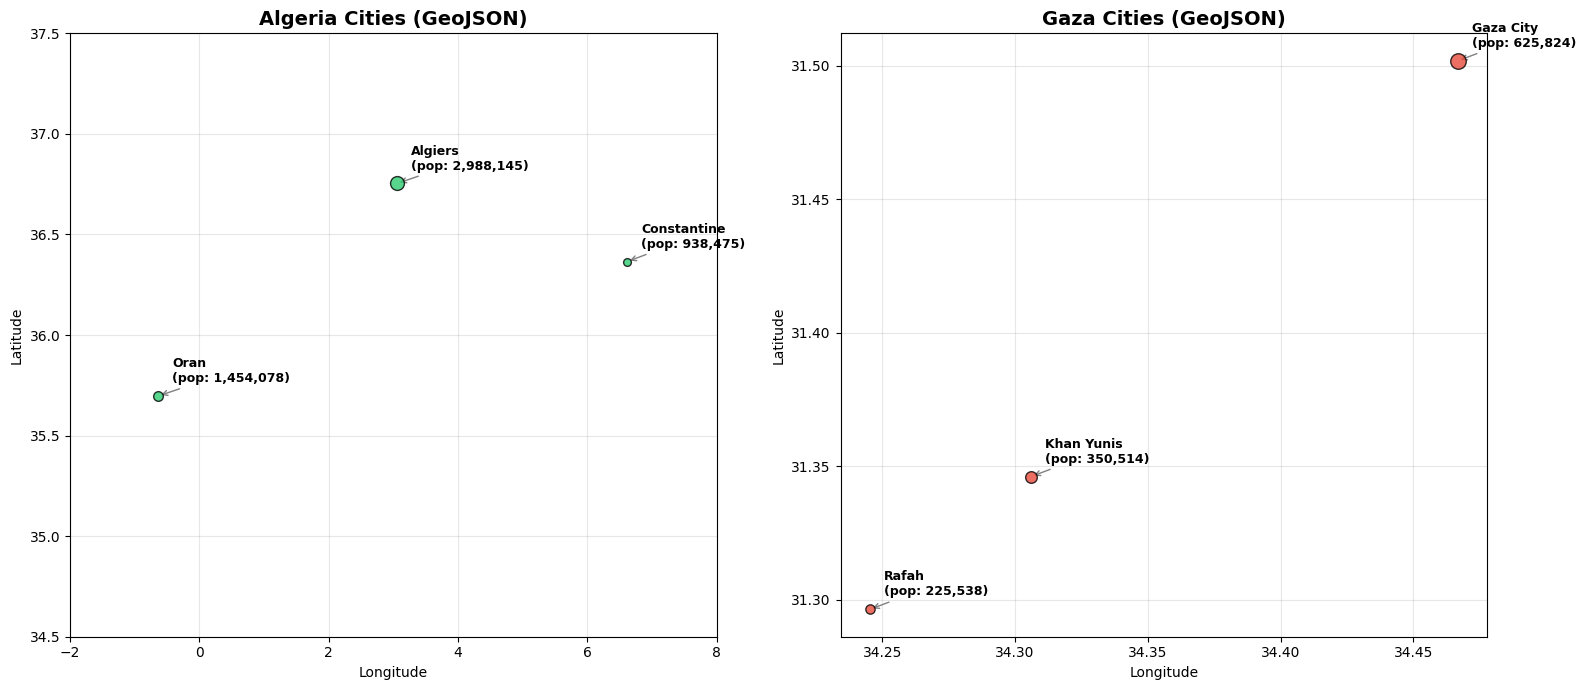

In [4]:
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(16,7))
for ax,gj,col,div,title in [(ax1,algeria_cities_geojson,"#2ecc71",30000,"Algeria Cities (GeoJSON)"),
                             (ax2,gaza_cities_geojson,"#e74c3c",5000,"Gaza Cities (GeoJSON)")]:
    for ft in gj["features"]:
        lon,lat=ft["geometry"]["coordinates"]; p=ft["properties"]
        ax.scatter(lon,lat,s=p["population"]/div,c=col,edgecolors="black",lw=1,zorder=5,alpha=.8)
        ax.annotate(f"{p['name']}\n(pop: {p['population']:,})",(lon,lat),textcoords="offset points",
                    xytext=(10,10),fontsize=9,fontweight="bold",arrowprops=dict(arrowstyle="->",color="gray"))
    ax.set_title(title,fontsize=14,fontweight="bold"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.grid(True,alpha=.3)
ax1.set_xlim(-2,8); ax1.set_ylim(34.5,37.5)
plt.tight_layout(); plt.savefig(os.path.join(data_dir,"geojson_cities.png"),dpi=150,bbox_inches="tight"); plt.show()

### A4 – Validator (fixed: handles `GeometryCollection`, checks Polygon ring closure)

In [5]:
VALID_TYPES=["Point","MultiPoint","LineString","MultiLineString","Polygon","MultiPolygon","GeometryCollection"]

def check_geom(g, label, errors, warnings):
    t=g.get("type")
    if t not in VALID_TYPES:
        errors.append(f"{label}: invalid geometry type '{t}'"); return
    if t=="GeometryCollection":
        gs=g.get("geometries")
        if not gs: errors.append(f"{label}: GeometryCollection missing 'geometries'")
        else:
            for k,sub in enumerate(gs): check_geom(sub,f"{label}.geometries[{k}]",errors,warnings)
        return
    c=g.get("coordinates")
    if c is None: errors.append(f"{label}: missing coordinates"); return
    if t=="Point":
        if len(c)<2: errors.append(f"{label}: Point needs at least 2 coordinates")
        else:
            lon,lat=c[0],c[1]
            if not -180<=lon<=180: warnings.append(f"{label}: longitude {lon} outside [-180, 180]")
            if not -90<=lat<=90: warnings.append(f"{label}: latitude {lat} outside [-90, 90]")
    elif t in ("Polygon","MultiPolygon"):
        polys=[c] if t=="Polygon" else c
        for pi,poly in enumerate(polys):
            for ri,ring in enumerate(poly):
                if len(ring)<4: errors.append(f"{label}: ring {pi}.{ri} has <4 positions")
                elif ring[0]!=ring[-1]: errors.append(f"{label}: ring {pi}.{ri} is not closed")

def validate_geojson(gj,name="GeoJSON"):
    errors,warnings=[],[]
    if gj.get("type")!="FeatureCollection": errors.append(f"Root type must be 'FeatureCollection', got '{gj.get('type')}'")
    feats=gj.get("features",[])
    if not feats: errors.append("No features found")
    for i,ft in enumerate(feats):
        if ft.get("type")!="Feature": errors.append(f"Feature {i}: type must be 'Feature'")
        g=ft.get("geometry")
        if g is None: errors.append(f"Feature {i}: missing geometry")
        else: check_geom(g,f"Feature {i}",errors,warnings)
        if "properties" not in ft: warnings.append(f"Feature {i}: missing properties")
    print(f"\nValidation Results for '{name}':"); print("-"*50)
    for e in errors: print("  ERROR:",e)
    for w in warnings: print("  WARNING:",w)
    if not errors and not warnings: print(f"  VALID: {len(feats)} features, no issues found")
    elif not errors: print(f"  VALID with warnings: {len(feats)} features")
    else: print(f"  INVALID: {len(errors)} error(s)")
    return not errors

validate_geojson(algeria_cities_geojson,"Algeria Cities")
validate_geojson(gaza_cities_geojson,"Gaza Cities")
validate_geojson({"type":"FeatureCollection","features":[{"type":"Feature","geometry":{"type":"Blob","coordinates":[0,0]},"properties":{}}]},"Invalid Test")
validate_geojson({"type":"FeatureCollection","features":[{"type":"Feature","geometry":{"type":"GeometryCollection","geometries":[{"type":"Point","coordinates":[1,2]}]},"properties":{}}]},"GeomCollection Test")
validate_geojson({"type":"FeatureCollection","features":[{"type":"Feature","geometry":{"type":"Polygon","coordinates":[[[0,0],[1,0],[1,1],[0,1]]]},"properties":{}}]},"Open Ring Test");


Validation Results for 'Algeria Cities':
--------------------------------------------------
  VALID: 3 features, no issues found

Validation Results for 'Gaza Cities':
--------------------------------------------------
  VALID: 3 features, no issues found

Validation Results for 'Invalid Test':
--------------------------------------------------
  ERROR: Feature 0: invalid geometry type 'Blob'
  INVALID: 1 error(s)

Validation Results for 'GeomCollection Test':
--------------------------------------------------
  VALID: 1 features, no issues found

Validation Results for 'Open Ring Test':
--------------------------------------------------
  ERROR: Feature 0: ring 0.0 is not closed
  INVALID: 1 error(s)


## Part B – Coordinate transformations

### B1 – WGS84 → UTM, with the **correct zone per city**
Zone = `floor((lon+180)/6)+1`; EPSG = 32600+zone (north). The handout forced zone 31N for all of Algeria, but Oran/Sidi Bel Abbès/Tlemcen (lon<0) are in 30N and Constantine/Batna (lon>6°E) in 32N.

In [6]:
from pyproj import CRS, Transformer, Geod

def utm_zone(lon): return int((lon+180)//6)+1
def utm_epsg(lon, lat): return (32600 if lat>=0 else 32700)+utm_zone(lon)
_tcache={}
def transformer_for(epsg):
    if epsg not in _tcache: _tcache[epsg]=Transformer.from_crs("EPSG:4326",f"EPSG:{epsg}",always_xy=True)
    return _tcache[epsg]

wgs84=CRS.from_epsg(4326); utm31n=CRS.from_epsg(32631)
for c,e in [(wgs84,4326),(utm31n,32631)]:
    print(f"EPSG:{e} | {c.name} | {'Geographic' if c.is_geographic else 'Projected'} | units: {c.axis_info[0].unit_name}")

algeria_cities={'Algiers':(3.0588,36.7538),'Oran':(-0.6331,35.6969),'Constantine':(6.6147,36.3650),
 'Sidi Bel Abbes':(-0.6308,35.1944),'Tlemcen':(-1.3150,34.8828),'Blida':(2.8283,36.4694),
 'Setif':(5.4078,36.1914),'Batna':(6.1747,35.5567)}

print("\nAlgeria: WGS84 -> UTM (zone chosen per city)")
print(f"{'City':<16}{'Lon':>9}{'Lat':>9}{'EPSG':>7}{'Easting (m)':>14}{'Northing (m)':>14}")
utm_coords_dz={}
for city,(lon,lat) in algeria_cities.items():
    ep=utm_epsg(lon,lat); e,n=transformer_for(ep).transform(lon,lat); utm_coords_dz[city]=(e,n,ep)
    print(f"{city:<16}{lon:>9.4f}{lat:>9.4f}{ep:>7}{e:>14.2f}{n:>14.2f}")

EPSG:4326 | WGS 84 | Geographic | units: degree
EPSG:32631 | WGS 84 / UTM zone 31N | Projected | units: metre

Algeria: WGS84 -> UTM (zone chosen per city)
City                  Lon      Lat   EPSG   Easting (m)  Northing (m)
Algiers            3.0588  36.7538  32631     505248.61    4067562.78
Oran              -0.6331  35.6969  32630     714155.98    3952912.99
Constantine        6.6147  36.3650  32632     285995.08    4027075.69
Sidi Bel Abbes    -0.6308  35.1944  32630     715701.67    3897172.84
Tlemcen           -1.3150  34.8828  32630     653985.69    3861341.31
Blida              2.8283  36.4694  32631     484617.31    4036027.52
Setif              5.4078  36.1914  32631     716503.15    4007864.98
Batna              6.1747  35.5567  32632     243911.10    3938455.19


### B2 – Gaza (UTM 36N)

In [7]:
gaza_cities={'Gaza City':(34.4668,31.5018),'Khan Yunis':(34.3061,31.3462),'Rafah':(34.2454,31.2965),
 'Jabalia':(34.4831,31.5282),'Deir al-Balah':(34.3506,31.4186)}
utm36n=CRS.from_epsg(32636); print("Target:",utm36n.name,"| units:",utm36n.axis_info[0].unit_name)
print(f"{'City':<16}{'Lon':>9}{'Lat':>9}{'EPSG':>7}{'Easting (m)':>14}{'Northing (m)':>14}")
utm_coords_gz={}
for city,(lon,lat) in gaza_cities.items():
    ep=utm_epsg(lon,lat); e,n=transformer_for(ep).transform(lon,lat); utm_coords_gz[city]=(e,n,ep)
    print(f"{city:<16}{lon:>9.4f}{lat:>9.4f}{ep:>7}{e:>14.2f}{n:>14.2f}")

Target: WGS 84 / UTM zone 36N | units: metre
City                  Lon      Lat   EPSG   Easting (m)  Northing (m)
Gaza City         34.4668  31.5018  32636     639297.96    3486147.96
Khan Yunis        34.3061  31.3462  32636     624240.46    3468707.35
Rafah             34.2454  31.2965  32636     618528.31    3463131.57
Jabalia           34.4831  31.5282  32636     640806.47    3489095.26
Deir al-Balah     34.3506  31.4186  32636     628375.27    3476783.66


### B3 – Euclidean distances in a **common** UTM zone
Cities in different zones can't be compared directly, so each pair is projected into the zone of the pair's mean longitude.

In [8]:
def utm_dist_m(c1,c2,coords):
    (lo1,la1),(lo2,la2)=coords[c1],coords[c2]
    ep=utm_epsg((lo1+lo2)/2,(la1+la2)/2); t=transformer_for(ep)
    x1,y1=t.transform(lo1,la1); x2,y2=t.transform(lo2,la2)
    return float(np.hypot(x2-x1,y2-y1)),ep

for label,coords in [("Algeria",algeria_cities),("Gaza",gaza_cities)]:
    print(f"\nDistances between {label} cities (UTM Euclidean):")
    names=list(coords)
    for i in range(len(names)):
        for j in range(i+1,len(names)):
            d,ep=utm_dist_m(names[i],names[j],coords)
            print(f"  {names[i]} <-> {names[j]}: {d/1000:.2f} km (EPSG:{ep})")


Distances between Algeria cities (UTM Euclidean):
  Algiers <-> Oran: 352.02 km (EPSG:32631)
  Algiers <-> Constantine: 321.24 km (EPSG:32631)
  Algiers <-> Sidi Bel Abbes: 375.05 km (EPSG:32631)
  Algiers <-> Tlemcen: 446.50 km (EPSG:32631)
  Algiers <-> Blida: 37.68 km (EPSG:32631)
  Algiers <-> Setif: 219.53 km (EPSG:32631)
  Algiers <-> Batna: 310.22 km (EPSG:32631)
  Oran <-> Constantine: 657.29 km (EPSG:32631)
  Oran <-> Sidi Bel Abbes: 55.76 km (EPSG:32630)
  Oran <-> Tlemcen: 109.57 km (EPSG:32630)
  Oran <-> Blida: 323.33 km (EPSG:32631)
  Oran <-> Setif: 547.69 km (EPSG:32631)
  Oran <-> Batna: 616.77 km (EPSG:32631)
  Constantine <-> Sidi Bel Abbes: 667.70 km (EPSG:32631)
  Constantine <-> Tlemcen: 736.80 km (EPSG:32631)
  Constantine <-> Blida: 339.77 km (EPSG:32631)
  Constantine <-> Setif: 110.19 km (EPSG:32632)
  Constantine <-> Batna: 98.11 km (EPSG:32632)
  Sidi Bel Abbes <-> Tlemcen: 71.36 km (EPSG:32630)
  Sidi Bel Abbes <-> Blida: 343.07 km (EPSG:32631)
  Sidi Bel 

### B4 – UTM vs geodesic (difference computed, not assumed)

In [9]:
geod=Geod(ellps="WGS84"); diffs=[]
print(f"{'City Pair':<34}{'UTM (km)':>10}{'Geodesic (km)':>15}{'Diff (%)':>10}"); print("-"*69)
pairs=[(algeria_cities,[('Algiers','Oran'),('Algiers','Constantine'),('Oran','Sidi Bel Abbes'),('Algiers','Sidi Bel Abbes')]),
       (gaza_cities,[('Gaza City','Khan Yunis'),('Gaza City','Rafah'),('Khan Yunis','Rafah'),('Jabalia','Rafah')])]
for coords,plist in pairs:
    for a,b in plist:
        u,_=utm_dist_m(a,b,coords); u/=1000
        _,_,g=geod.inv(*coords[a],*coords[b]); g/=1000
        d=abs(u-g)/g*100; diffs.append(d)
        print(f"{a+' <-> '+b:<34}{u:>10.2f}{g:>15.2f}{d:>9.3f}%")
    print("-"*69)
print(f"Max difference: {max(diffs):.3f}%  (UTM scale factor 0.9996 at the central meridian, ~1.0010 at zone edges)")

City Pair                           UTM (km)  Geodesic (km)  Diff (%)
---------------------------------------------------------------------
Algiers <-> Oran                      352.02         352.00    0.004%
Algiers <-> Constantine               321.24         321.22    0.004%
Oran <-> Sidi Bel Abbes                55.76          55.75    0.017%
Algiers <-> Sidi Bel Abbes            375.05         375.03    0.004%
---------------------------------------------------------------------
Gaza City <-> Khan Yunis               23.04          23.05    0.019%
Gaza City <-> Rafah                    31.00          31.01    0.019%
Khan Yunis <-> Rafah                    7.98           7.98    0.022%
Jabalia <-> Rafah                      34.21          34.22    0.019%
---------------------------------------------------------------------
Max difference: 0.022%  (UTM scale factor 0.9996 at the central meridian, ~1.0010 at zone edges)


### B5 – Cross-region distance

In [10]:
lon1,lat1=algeria_cities['Algiers']; lon2,lat2=gaza_cities['Gaza City']
az12,az21,dist=geod.inv(lon1,lat1,lon2,lat2)
print(f"Algiers ({lat1}N, {lon1}E) -> Gaza City ({lat2}N, {lon2}E)")
print(f"Geodesic distance: {dist/1000:.2f} km | forward azimuth {az12:.2f}° | back azimuth {az21:.2f}°")
print("\nUTM Euclidean is invalid here: the points are ~28° of longitude apart (zones 31N vs 36N).")

Algiers (36.7538N, 3.0588E) -> Gaza City (31.5018N, 34.4668E)
Geodesic distance: 2941.46 km | forward azimuth 92.11° | back azimuth -69.94°

UTM Euclidean is invalid here: the points are ~28° of longitude apart (zones 31N vs 36N).


## Part C – Vector formats with Fiona
GADM 4.1 serves GeoJSON as `.json.zip` (the handout's `.json` URL may 404). The helper tries both and, if the network is blocked, builds a small **fallback** layer (buffered city points) so the rest of the part still runs. A warning is printed when the fallback is used.

In [12]:
!pip install fiona

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 74.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [fiona]


In [14]:
import fiona, urllib.request, zipfile, io
from shapely.geometry import Point, mapping

def fallback_layer(path, cities, level_name):
    schema={"geometry":"Polygon","properties":{"GID_1":"str","NAME_1":"str"}}
    with fiona.open(path,"w",driver="GeoJSON",schema=schema,crs="EPSG:4326") as dst:
        for i,(n,(lon,lat)) in enumerate(cities.items()):
            dst.write({"type":"Feature","geometry":mapping(Point(lon,lat).buffer(0.1)),
                       "properties":{"GID_1":f"{level_name}.{i+1}","NAME_1":n}})

def get_gadm(iso, cities):
    path=os.path.join(data_dir,f"gadm41_{iso}_1.json")
    if os.path.exists(path): print("File exists:",path); return path
    base=f"https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_{iso}_1.json"
    for url in (base+".zip", base):
        try:
            raw=urllib.request.urlopen(url,timeout=30).read()
            if url.endswith(".zip"): raw=zipfile.ZipFile(io.BytesIO(raw)).read(f"gadm41_{iso}_1.json")
            open(path,"wb").write(raw); print("Downloaded:",url); return path
        except Exception as e: print(f"  failed {url}: {type(e).__name__}")
    print(f"WARNING: GADM unavailable -> using FALLBACK layer for {iso} (not real boundaries)")
    fallback_layer(path,cities,iso); return path

def inspect_vector(path, title, list_n=None):
    print("\n"+"="*60+f"\n{title}\n"+"="*60)
    with fiona.open(path) as src:
        print(f"Driver: {src.driver}\nCRS: {src.crs}\nFeatures: {len(src)}")
        b=src.bounds; print(f"Bounds: min_lon={b[0]:.4f}, min_lat={b[1]:.4f}, max_lon={b[2]:.4f}, max_lat={b[3]:.4f}")
        print(f"Geometry type: {src.schema['geometry']}\nProperties ({len(src.schema['properties'])}):")
        for k,v in src.schema["properties"].items(): print(f"  {k}: {v}")
        print("Features:")
        for i,ft in enumerate(src):
            if list_n and i>=list_n: print(f"  ... and {len(src)-list_n} more"); break
            print(f"  {i+1:2d}. {ft['properties'].get('NAME_1','Unknown')} ({ft['geometry']['type']})")

### C1 – Palestine / Gaza

In [15]:
gaza_file=get_gadm("PSE",gaza_cities)
inspect_vector(gaza_file,"GAZA / PALESTINE DATA INSPECTION (Fiona)")

Downloaded: https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_PSE_1.json.zip

GAZA / PALESTINE DATA INSPECTION (Fiona)
Driver: GeoJSON
CRS: EPSG:4326
Features: 2
Bounds: min_lon=34.2293, min_lat=31.2236, max_lon=35.5755, max_lat=32.5516
Geometry type: MultiPolygon
Properties (11):
  GID_1: str
  GID_0: str
  COUNTRY: str
  NAME_1: str
  VARNAME_1: str
  NL_NAME_1: str
  TYPE_1: str
  ENGTYPE_1: str
  CC_1: str
  HASC_1: str
  ISO_1: str
Features:
   1. Gaza (MultiPolygon)
   2. WestBank (MultiPolygon)


### C2 – Algeria

In [16]:
algeria_file=get_gadm("DZA",algeria_cities)
inspect_vector(algeria_file,"ALGERIA DATA INSPECTION (Fiona)",list_n=10)

Downloaded: https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_DZA_1.json.zip

ALGERIA DATA INSPECTION (Fiona)
Driver: GeoJSON
CRS: EPSG:4326
Features: 48
Bounds: min_lon=-8.6739, min_lat=18.9602, max_lon=11.9874, max_lat=37.0887
Geometry type: MultiPolygon
Properties (11):
  GID_1: str
  GID_0: str
  COUNTRY: str
  NAME_1: str
  VARNAME_1: str
  NL_NAME_1: str
  TYPE_1: str
  ENGTYPE_1: str
  CC_1: str
  HASC_1: str
  ISO_1: str
Features:
   1. Adrar (MultiPolygon)
   2. AïnDefla (MultiPolygon)
   3. AïnTémouchent (MultiPolygon)
   4. Alger (MultiPolygon)
   5. Annaba (MultiPolygon)
   6. Batna (MultiPolygon)
   7. Béchar (MultiPolygon)
   8. Béjaïa (MultiPolygon)
   9. Biskra (MultiPolygon)
  10. Blida (MultiPolygon)
  ... and 38 more


### C3 – GeoJSON → GeoPackage

In [17]:
def to_gpkg(inp,out,layer):
    if os.path.exists(out): os.remove(out)
    with fiona.open(inp) as src:
        with fiona.open(out,"w",driver="GPKG",schema=src.schema,crs=src.crs,layer=layer) as dst:
            n=0
            for ft in src: dst.write(ft); n+=1
    print(f"Converted {n} features -> {out} ({os.path.getsize(out)/1024:.1f} KB)")
    with fiona.open(out,layer=layer) as chk:
        print(f"  verify: driver={chk.driver}, layer={layer}, features={len(chk)}, crs={chk.crs}, geom={chk.schema['geometry']}")

to_gpkg(gaza_file,os.path.join(data_dir,"palestine_admin.gpkg"),"admin_level_1")
to_gpkg(algeria_file,os.path.join(data_dir,"algeria_admin.gpkg"),"wilayas")

Converted 2 features -> data/palestine_admin.gpkg (96.0 KB)
  verify: driver=GPKG, layer=admin_level_1, features=2, crs=EPSG:4326, geom=MultiPolygon
Converted 48 features -> data/algeria_admin.gpkg (412.0 KB)
  verify: driver=GPKG, layer=wilayas, features=48, crs=EPSG:4326, geom=MultiPolygon


### C4 – Compare formats

In [18]:
print(f"{'File':<34}{'Format':<12}{'Size (KB)':>10}"); print("-"*56)
for fn,fmt in [("gadm41_PSE_1.json","GeoJSON"),("palestine_admin.gpkg","GeoPackage"),("gadm41_DZA_1.json","GeoJSON"),("algeria_admin.gpkg","GeoPackage")]:
    p=os.path.join(data_dir,fn)
    print(f"{fn:<34}{fmt:<12}{(os.path.getsize(p)/1024 if os.path.exists(p) else float('nan')):>10.1f}")

File                              Format       Size (KB)
--------------------------------------------------------
gadm41_PSE_1.json                 GeoJSON            3.8
palestine_admin.gpkg              GeoPackage        96.0
gadm41_DZA_1.json                 GeoJSON          304.2
algeria_admin.gpkg                GeoPackage       412.0


## Part D – Raster metadata with Rasterio

### D1 – SRTM info
SRTM needs NASA Earthdata login, so we use synthetic DEMs. Tiles: `N36E003` (Algiers, 36–37N / 3–4E), `N31E034` (Gaza, 31–32N / 34–35E); 1 arc-second ≈ 30 m, 3601×3601 px. Register at https://urs.earthdata.nasa.gov/users/new

### D2 – Synthetic GeoTIFFs
Changes: removed `AREA_OR_POINT='Point'` (`from_bounds` builds a corner-aligned PixelIsArea grid, so the tag could shift georeferencing by half a pixel); added a block of real nodata cells so the nodata logic is exercised.

In [19]:
import rasterio
from rasterio.transform import from_bounds
NODATA=-9999.0
np.random.seed(42); height=width=360
y=np.linspace(0,1,height).reshape(-1,1); x=np.linspace(0,1,width).reshape(1,-1)

algeria_dem=np.clip((800*y+200*np.sin(8*np.pi*x)+150*np.sin(6*np.pi*y)+50*np.random.randn(height,width)),0,1500).astype(np.float32)
algeria_dem[:20,:20]=NODATA
gaza_dem=np.clip((30*x+15*np.sin(10*np.pi*x)+10*np.sin(12*np.pi*y)+5*np.random.randn(height,width)+20),0,100).astype(np.float32)
gaza_dem[-20:,-20:]=NODATA

def write_tif(path,arr,bounds,tags):
    w,s,e,n=bounds
    with rasterio.open(path,"w",driver="GTiff",height=height,width=width,count=1,dtype="float32",
                       crs="EPSG:4326",transform=from_bounds(w,s,e,n,width,height),nodata=NODATA) as dst:
        dst.write(arr,1); dst.update_tags(**tags)
    print(f"Created {path} ({os.path.getsize(path)/1024:.1f} KB)")

algeria_tif=os.path.join(data_dir,"algeria_dem_synthetic.tif"); gaza_tif=os.path.join(data_dir,"gaza_dem_synthetic.tif")
write_tif(algeria_tif,algeria_dem,(2.5,36.0,3.5,37.0),dict(description="Synthetic DEM for Algeria (Algiers area)",source="Lab exercise - not real data"))
write_tif(gaza_tif,gaza_dem,(34.2,31.2,34.6,31.6),dict(description="Synthetic DEM for Gaza Strip",source="Lab exercise - not real data"))

Created data/algeria_dem_synthetic.tif (508.0 KB)
Created data/gaza_dem_synthetic.tif (508.0 KB)


### D3 – Inspect metadata

In [20]:
def inspect_raster(fp):
    print(f"\n{'='*60}\nRASTER METADATA: {os.path.basename(fp)}\n{'='*60}")
    with rasterio.open(fp) as src:
        print(f"Driver: {src.driver} | size: {os.path.getsize(fp)/1024:.1f} KB")
        print(f"Dimensions: {src.width} x {src.height} px ({src.width*src.height:,} total), bands: {src.count}")
        print(f"dtype: {src.dtypes[0]} | nodata: {src.nodata}")
        print(f"CRS: {src.crs} | EPSG: {src.crs.to_epsg()} | geographic: {src.crs.is_geographic} | projected: {src.crs.is_projected}")
        b=src.bounds; print(f"Bounds: W={b.left:.6f} S={b.bottom:.6f} E={b.right:.6f} N={b.top:.6f}")
        unit="degrees" if src.crs.is_geographic else "m"
        print(f"Resolution: {src.res[0]:.6f} x {src.res[1]:.6f} {unit}")
        if src.crs.is_geographic:
            lat=(b.top+b.bottom)/2
            print(f"  ~{src.res[0]*111320*np.cos(np.radians(lat)):.1f} m (E-W) x {src.res[1]*110574:.1f} m (N-S) at lat {lat:.1f}")
        t=src.transform; print(f"Affine: {t}\n  upper-left=({t.c:.6f}, {t.f:.6f}), pixel size=({t.a:.6f}, {t.e:.6f})")
        if src.tags(): print("Tags:",src.tags())
        a=src.read(1); v=a[a!=src.nodata] if src.nodata is not None else a
        print(f"nodata cells: {a.size-v.size:,}")
        print(f"Stats (valid): min={v.min():.2f} max={v.max():.2f} mean={v.mean():.2f} std={v.std():.2f} median={np.median(v):.2f}")
inspect_raster(algeria_tif); inspect_raster(gaza_tif)


RASTER METADATA: algeria_dem_synthetic.tif
Driver: GTiff | size: 508.0 KB
Dimensions: 360 x 360 px (129,600 total), bands: 1
dtype: float32 | nodata: -9999.0
CRS: EPSG:4326 | EPSG: 4326 | geographic: True | projected: False
Bounds: W=2.500000 S=36.000000 E=3.500000 N=37.000000
Resolution: 0.002778 x 0.002778 degrees
  ~248.6 m (E-W) x 307.2 m (N-S) at lat 36.5
Affine: | 0.00, 0.00, 2.50|
| 0.00,-0.00, 37.00|
| 0.00, 0.00, 1.00|
  upper-left=(2.500000, 37.000000), pixel size=(0.002778, -0.002778)
Tags: {'description': 'Synthetic DEM for Algeria (Algiers area)', 'source': 'Lab exercise - not real data', 'AREA_OR_POINT': 'Area'}
nodata cells: 400
Stats (valid): min=0.00 max=1117.09 mean=407.36 std=261.78 median=401.39

RASTER METADATA: gaza_dem_synthetic.tif
Driver: GTiff | size: 508.0 KB
Dimensions: 360 x 360 px (129,600 total), bands: 1
dtype: float32 | nodata: -9999.0
CRS: EPSG:4326 | EPSG: 4326 | geographic: True | projected: False
Bounds: W=34.200000 S=31.200000 E=34.600000 N=31.600

### D4 – Visualize (nodata masked)

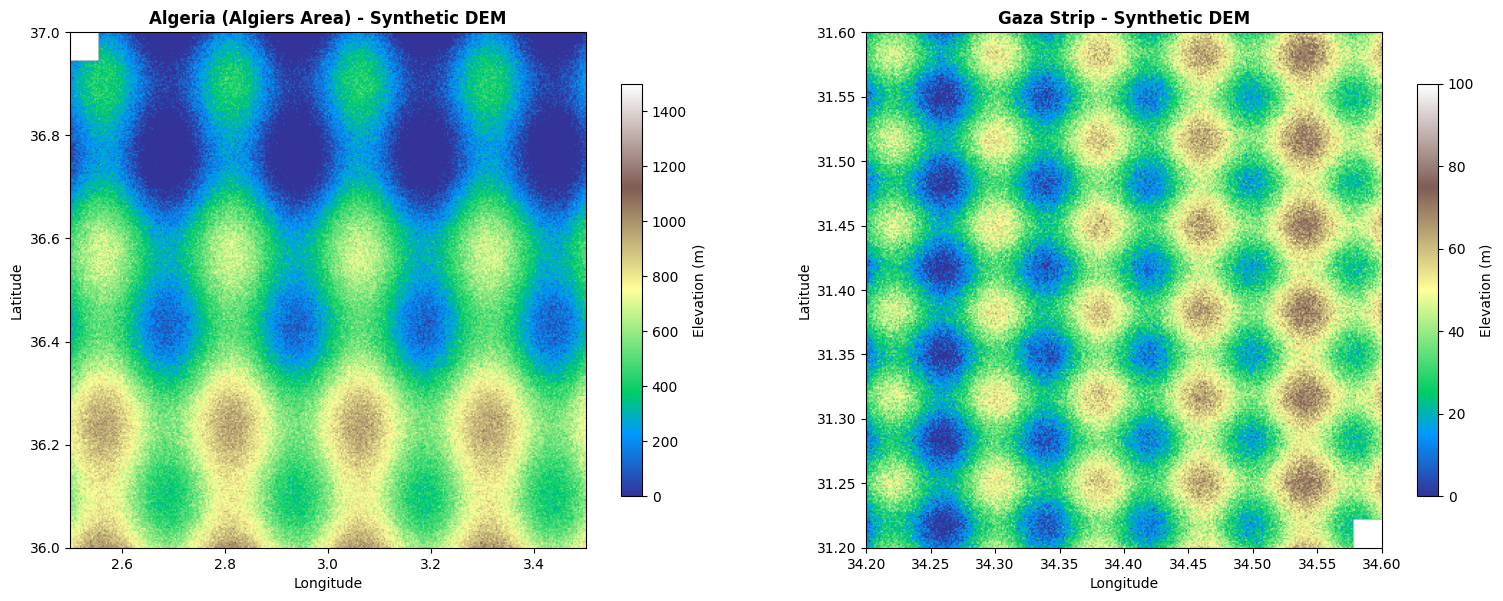

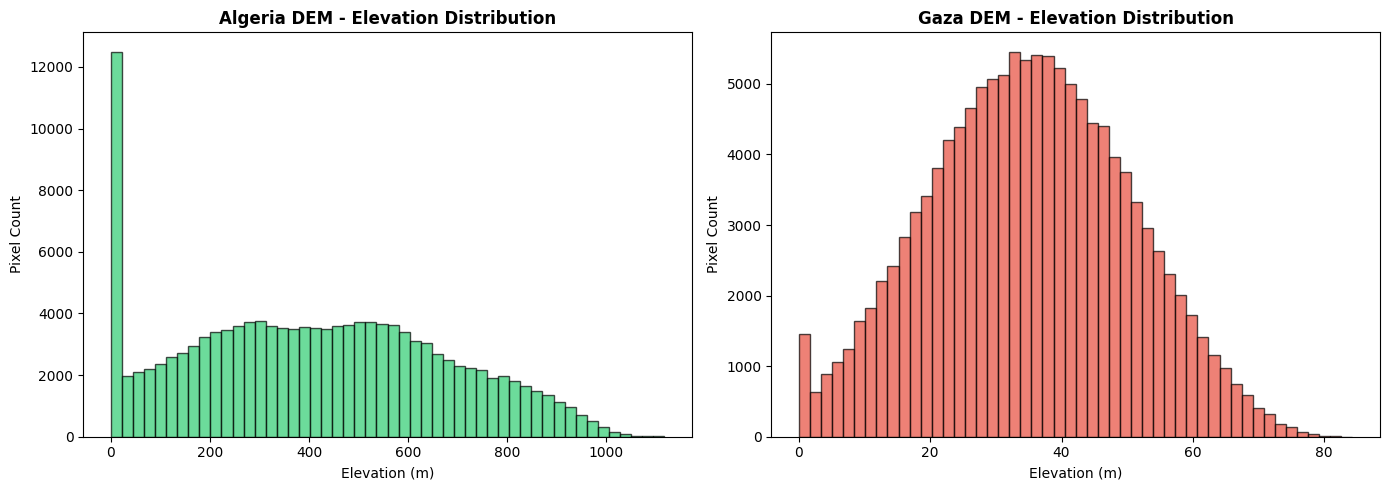

In [21]:
def load_masked(fp):
    with rasterio.open(fp) as s:
        a=s.read(1,masked=True); b=s.bounds
    return a,[b.left,b.right,b.bottom,b.top]
dz,ext_dz=load_masked(algeria_tif); gz,ext_gz=load_masked(gaza_tif)
fig,axes=plt.subplots(1,2,figsize=(16,6))
for ax,a,ext,vmax,t in [(axes[0],dz,ext_dz,1500,"Algeria (Algiers Area) - Synthetic DEM"),(axes[1],gz,ext_gz,100,"Gaza Strip - Synthetic DEM")]:
    im=ax.imshow(a,cmap="terrain",extent=ext,origin="upper",vmin=0,vmax=vmax)
    ax.set_title(t,fontweight="bold"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    plt.colorbar(im,ax=ax,label="Elevation (m)",shrink=.8)
plt.tight_layout(); plt.savefig(os.path.join(data_dir,"dem_comparison.png"),dpi=150,bbox_inches="tight"); plt.show()
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,a,c,t in [(axes[0],dz,"#2ecc71","Algeria DEM"),(axes[1],gz,"#e74c3c","Gaza DEM")]:
    ax.hist(a.compressed(),bins=50,color=c,edgecolor="black",alpha=.7); ax.set_title(t+" - Elevation Distribution",fontweight="bold")
    ax.set_xlabel("Elevation (m)"); ax.set_ylabel("Pixel Count")
plt.tight_layout(); plt.savefig(os.path.join(data_dir,"dem_histograms.png"),dpi=150,bbox_inches="tight"); plt.show()

### D5 – Windows and pixels
Single-pixel reads use a 1×1 `Window` instead of loading the whole raster.

In [22]:
from rasterio.windows import Window
from rasterio.transform import xy, rowcol
with rasterio.open(algeria_tif) as src:
    r0,c0=src.height//2-50,src.width//2-50
    win=Window(c0,r0,100,100); sub=src.read(1,window=win,masked=True)
    print("Windowed read (center 100x100):")
    print(f"  offset row={r0}, col={c0}, shape={sub.shape}")
    print(f"  bounds={rasterio.windows.bounds(win,src.transform)}")
    print(f"  elevation {sub.min():.1f} - {sub.max():.1f} m, mean {sub.mean():.1f} m")
    lon,lat=xy(src.transform,180,180); print(f"\nPixel (180,180) center -> lon {lon:.6f}, lat {lat:.6f}")
    row,col=rowcol(src.transform,3.0,36.5); print(f"(3.0E, 36.5N) -> row {row}, col {col}")
    if 0<=row<src.height and 0<=col<src.width:
        v=src.read(1,window=Window(col,row,1,1))[0,0]; print(f"  elevation: {v:.1f} m")

Windowed read (center 100x100):
  offset row=130, col=130, shape=(100, 100)
  bounds=(2.861111111111111, 36.361111111111114, 3.138888888888889, 36.638888888888886)
  elevation 0.0 - 820.0 m, mean 400.6 m

Pixel (180,180) center -> lon 3.001389, lat 36.498611
(3.0E, 36.5N) -> row 180, col 180
  elevation: 455.9 m
